# Stage 1 Binary Gatekeeper: Cassava Leaf Detector
### Mobile Production Architecture: Out-of-Distribution (OOD) Prevention

**System Architecture:**
```
 [ Camera Frame ] ──> [ STAGE 1: Cassava Gatekeeper (~3 ms) ]
                             │
              Is it a Cassava Leaf? (Sigmoid P >= 0.70)
                      ┌──────┴──────┐
                      ▼             ▼
                     YES           NO ──> [ Prompt Farmer: ]
                      │                   "No cassava leaf detected."
                      ▼
 [ STAGE 2: Model 4 (D-CLAHE) 5-Class Disease Diagnosis (~20 ms) ]
```

**Pipeline Overview:**
1. Mount Google Drive & unpack cassava dataset (Class 1: `1_cassava`, ~4,800 images)
2. Download online real-world non-cassava images via MS-COCO (Class 0: `0_non_cassava`, ~4,000 images)
3. Train lightweight MobileNetV3-Small binary classifier (~1.5 MB, ~3 ms latency)
4. Benchmark precision, recall, and plot confusion matrix (Threshold $\tau = 0.70$)
5. Export `cassava_gatekeeper.tflite` and auto-save directly to Google Drive (`/content/drive/MyDrive/DCLAHE_MobileNetV3/`)
6. Android Kotlin integration blueprint for the Two-Stage Cascaded pipeline


In [ ]:
# ── CELL 1: ENVIRONMENT SETUP & GOOGLE DRIVE MOUNT ────────────────────────────
import os
import sys
import shutil
import glob
import random
import time
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, models
from google.colab import drive

# Set random seeds for absolute reproducibility
SEED = 42
tf.random.set_seed(SEED)
np.random.seed(SEED)
random.seed(SEED)

# Mount Google Drive to access your cassava dataset
drive.mount('/content/drive', force_remount=True)

print(f"TensorFlow Version: {tf.__version__}")
gpus = tf.config.list_physical_devices('GPU')
print(f"GPU Available: {len(gpus)} ({gpus[0].name if gpus else 'Running on CPU'})")


Mounted at /content/drive
TensorFlow Version: 2.21.0
GPU Available: 1 (/physical_device:GPU:0)


In [ ]:
# ── CELL 2: RETRIEVE CASSAVA IMAGES FROM GOOGLE DRIVE (Class 1) ───────────────
CASSAVA_ZIP = "/content/drive/MyDrive/DCLAHE_MobileNetV3/cassavadata.zip"
CASSAVA_RAW_DIR = "/content/local_cassava_raw"
BINARY_DIR = "/content/dataset_binary"

# We prefix folders with numbers so Keras directory loader assigns:
# Index 0 -> '0_non_cassava' (Negative)
# Index 1 -> '1_cassava'     (Positive)
CLASS_0_DIR = os.path.join(BINARY_DIR, "0_non_cassava")
CLASS_1_DIR = os.path.join(BINARY_DIR, "1_cassava")
os.makedirs(CLASS_0_DIR, exist_ok=True)
os.makedirs(CLASS_1_DIR, exist_ok=True)

if not os.path.exists(CASSAVA_ZIP):
    raise FileNotFoundError(f"Cassava zip not found at {CASSAVA_ZIP}. Verify file path in Drive!")

print(f"Unpacking cassava dataset from {CASSAVA_ZIP}...")
!unzip -q "{CASSAVA_ZIP}" -d "{CASSAVA_RAW_DIR}"

# Robustly scan all files at any nested folder depth
cassava_image_paths = []
for root, _, files in os.walk(CASSAVA_RAW_DIR):
    for f in files:
        if f.lower().endswith(('.jpg', '.jpeg', '.png')):
            cassava_image_paths.append(os.path.join(root, f))

print(f"Found {len(cassava_image_paths)} total cassava images across all disease subfolders.")

# Stage images with index prefixes to prevent filename collisions
for idx, img_path in enumerate(cassava_image_paths):
    base_name = os.path.basename(img_path)
    dest = os.path.join(CLASS_1_DIR, f"cassava_{idx}_{base_name}")
    if not os.path.exists(dest):
        try:
            os.symlink(img_path, dest)
        except:
            shutil.copyfile(img_path, dest)

total_cassava = len(os.listdir(CLASS_1_DIR))
print(f"Successfully staged {total_cassava} Cassava images into {CLASS_1_DIR} (Class 1: Positive)")


Unpacking cassava dataset from /content/drive/MyDrive/DCLAHE_MobileNetV3/cassavadata.zip...
Found 4802 total cassava images across all disease subfolders.
Successfully staged 4802 Cassava images into /content/dataset_binary/1_cassava (Class 1: Positive)


In [ ]:
# ── CELL 3: AUTOMATICALLY RETRIEVE REAL-WORLD NON-CASSAVA OBJECTS (Class 0) ───
# Downloads official MS-COCO validation set (~5,000 diverse real-world images:
# human hands, shoes, clothing, soil, terrain, foliage, animals, vehicles, indoor objects)
COCO_ZIP = "val2017.zip"
TEMP_COCO = "/content/temp_coco"

if not os.path.exists(COCO_ZIP) and not os.path.exists(TEMP_COCO):
    print("Downloading MS-COCO real-world negative dataset (~780 MB)... takes ~15 seconds in Colab")
    !wget -q --show-progress http://images.cocodataset.org/zips/val2017.zip
    !unzip -q val2017.zip -d "{TEMP_COCO}"
    !rm -f val2017.zip

# Gather all negative images
coco_files = []
for root, _, files in os.walk(TEMP_COCO):
    for f in files:
        if f.lower().endswith(('.jpg', '.jpeg', '.png')):
            coco_files.append(os.path.join(root, f))

print(f"Found {len(coco_files)} available non-cassava online images.")

# Sample balanced count (~4,000 images) matching the cassava dataset
NUM_NEGATIVES = min(4000, len(coco_files))
selected_negatives = random.sample(coco_files, NUM_NEGATIVES)

print(f"Staging {NUM_NEGATIVES} negative images into {CLASS_0_DIR}...")
for idx, f in enumerate(selected_negatives):
    base_name = os.path.basename(f)
    dest = os.path.join(CLASS_0_DIR, f"non_cassava_{idx}_{base_name}")
    if not os.path.exists(dest):
        shutil.copyfile(f, dest)

# Clean up temporary download folder to free Colab disk space
shutil.rmtree(TEMP_COCO, ignore_errors=True)

total_non_cassava = len(os.listdir(CLASS_0_DIR))
total_cassava = len(os.listdir(CLASS_1_DIR))

print("\n==================================================")
print("BINARY DATASET READY FOR TRAINING")
print(f"  • Class 0 (Non-Cassava Objects): {total_non_cassava} images")
print(f"  • Class 1 (Cassava Leaves):      {total_cassava} images")
print(f"  • Total Binary Dataset:          {total_cassava + total_non_cassava} images")
print("==================================================")


val2017.zip         100%[===================>] 777.80M  57.7MB/s    in 14s     
Found 5000 available non-cassava online images.
Staging 4000 negative images into /content/dataset_binary/0_non_cassava...

BINARY DATASET READY FOR TRAINING
  • Class 0 (Non-Cassava Objects): 4000 images
  • Class 1 (Cassava Leaves):      4802 images
  • Total Binary Dataset:          8802 images


In [ ]:
# ── CELL 4: DATA LOADERS & ROBUST FIELD DATA AUGMENTATION ─────────────────────
IMG_SIZE = (224, 224)
BATCH_SIZE = 32

print("Creating Train (80%) and Validation (20%) data pipelines...")
train_ds = tf.keras.utils.image_dataset_from_directory(
    BINARY_DIR,
    validation_split=0.2,
    subset="training",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode='binary'
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    BINARY_DIR,
    validation_split=0.2,
    subset="validation",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode='binary'
)

class_names = train_ds.class_names
print(f"Confirmed Class Mapping: 0 = {class_names[0]}, 1 = {class_names[1]}")
assert class_names[0] == '0_non_cassava' and class_names[1] == '1_cassava', 'Class order check failed!'

# Data augmentation ensures gatekeeper handles varying orientations, zoom, and framing
data_aug = tf.keras.Sequential([
    layers.RandomFlip("horizontal_and_vertical"),
    layers.RandomRotation(0.20),
    layers.RandomZoom(0.15),
    layers.RandomTranslation(0.10, 0.10)
], name="binary_gatekeeper_aug")

train_ds = train_ds.map(lambda x, y: (data_aug(x, training=True), y), num_parallel_calls=tf.data.AUTOTUNE)
train_ds = train_ds.prefetch(tf.data.AUTOTUNE)
val_ds = val_ds.prefetch(tf.data.AUTOTUNE)

print(f"Training Batches: {len(train_ds)} | Validation Batches: {len(val_ds)}")


Creating Train (80%) and Validation (20%) data pipelines...
Found 8802 files belonging to 2 classes.
Using 7042 files for training.
Found 8802 files belonging to 2 classes.
Using 1760 files for validation.
Confirmed Class Mapping: 0 = 0_non_cassava, 1 = 1_cassava
Training Batches: 221 | Validation Batches: 55


In [ ]:
# ── CELL 5: BUILD LIGHTWEIGHT GATEKEEPER MODEL (MobileNetV3-Small) ────────────
# Ultra-compact model: ~1.5 MB total size, ~3 ms execution time on mobile devices
inputs = layers.Input(shape=(224, 224, 3), name="camera_frame_input")

# Rescale raw input pixels [0, 255] directly into [-1.0, 1.0] inside the model graph
# (This means Android app can feed raw bitmaps without custom normalization code!)
x = layers.Rescaling(scale=1.0 / 127.5, offset=-1.0, name="rescaling")(inputs)

base_backbone = tf.keras.applications.MobileNetV3Small(
    input_shape=(224, 224, 3),
    include_top=False,
    weights='imagenet',
    pooling='avg'
)

# Freeze early low-level layers; fine-tune high-level semantic filters
base_backbone.trainable = True
for layer in base_backbone.layers[:60]:
    layer.trainable = False

x = base_backbone(x)
x = layers.Dropout(0.35, name="head_dropout")(x)
x = layers.Dense(128, activation='relu', name="dense_projection")(x)
# Single sigmoid output: Probability [0.0 to 1.0] that image IS a Cassava Leaf
outputs = layers.Dense(1, activation='sigmoid', name="is_cassava_probability")(x)

gatekeeper = models.Model(inputs=inputs, outputs=outputs, name="Cassava_Gatekeeper_MobileNetV3")

gatekeeper.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=3e-4),
    loss='binary_crossentropy',
    metrics=[
        'accuracy',
        tf.keras.metrics.Precision(name='precision'),
        tf.keras.metrics.Recall(name='recall'),
        tf.keras.metrics.AUC(name='auc')
    ]
)

gatekeeper.summary()


4334752/4334752 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "Cassava_Gatekeeper_MobileNetV3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ camera_frame_input (InputLayer) │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ MobileNetV3Small (Functional)   │ (None, 576)            │       939,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ head_dropout (Dropout)          │ (None, 576)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_projection (Dense)        │ (None, 128)            │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ is_cassava_probability (Dense)  │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,013,105 (3.86 MB)

 Trainable params: 929,185 (3.54 MB)

 Non-trainable params: 83,920 (327.81 KB)

Starting Gatekeeper Training (takes ~3 to 5 minutes on Colab GPU)...
Epoch 1/15
221/221 ━━━━━━━━━━━━━━━━━━━━ 0s 543ms/step - accuracy: 0.8598 - auc: 0.9314 - loss: 0.3098 - precision: 0.8662 - recall: 0.8762
Epoch 1: val_accuracy improved from None to 0.47443, saving model to best_gatekeeper.keras

Epoch 1: finished saving model to best_gatekeeper.keras
221/221 ━━━━━━━━━━━━━━━━━━━━ 177s 591ms/step - accuracy: 0.9047 - auc: 0.9683 - loss: 0.2266 - precision: 0.9094 - recall: 0.9163 - val_accuracy: 0.4744 - val_auc: 0.7297 - val_loss: 0.6836 - val_precision: 0.6752 - val_recall: 0.0818
Epoch 2/15
220/221 ━━━━━━━━━━━━━━━━━━━━ 0s 447ms/step - accuracy: 0.9441 - auc: 0.9880 - loss: 0.1419 - precision: 0.9372 - recall: 0.9617
Epoch 2: val_accuracy improved from 0.47443 to 0.59545, saving model to best_gatekeeper.keras

Epoch 2: finished saving model to best_gatekeeper.keras
221/221 ━━━━━━━━━━━━━━━━━━━━ 104s 469ms/step - accuracy: 0.9490 - auc: 0.9892 - loss: 0.1317 - precision: 0.9486 - reca

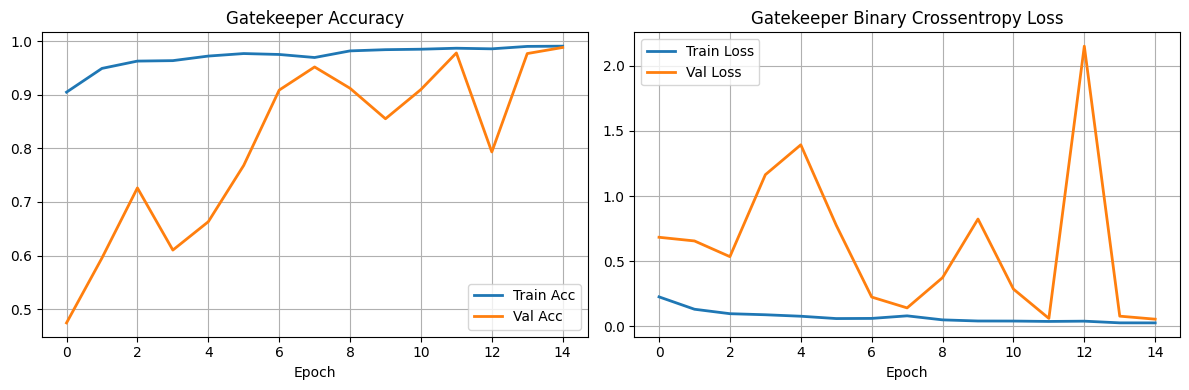

In [ ]:
# ── CELL 6: TRAIN GATEKEEPER CLASSIFIER ────────────────────────────────────────
EPOCHS = 15

callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor='val_accuracy',
        patience=4,
        restore_best_weights=True,
        verbose=1
    ),
    tf.keras.callbacks.ModelCheckpoint(
        'best_gatekeeper.keras',
        monitor='val_accuracy',
        save_best_only=True,
        verbose=1
    )
]

print("Starting Gatekeeper Training (takes ~3 to 5 minutes on Colab GPU)...")
history = gatekeeper.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=callbacks
)

# Plot training trajectories
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ax1.plot(history.history['accuracy'], label='Train Acc', lw=2)
ax1.plot(history.history['val_accuracy'], label='Val Acc', lw=2)
ax1.set_title('Gatekeeper Accuracy')
ax1.set_xlabel('Epoch')
ax1.legend()
ax1.grid(True)

ax2.plot(history.history['loss'], label='Train Loss', lw=2)
ax2.plot(history.history['val_loss'], label='Val Loss', lw=2)
ax2.set_title('Gatekeeper Binary Crossentropy Loss')
ax2.set_xlabel('Epoch')
ax2.legend()
ax2.grid(True)
plt.tight_layout()
plt.savefig('gatekeeper_training_curve.png', dpi=200)
plt.show()


In [ ]:
# ── CELL 7: BENCHMARK GATEKEEPER & PLOT CONFUSION MATRIX ──────────────────────
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

print("Evaluating best gatekeeper model on validation data...")
all_preds = []
all_labels = []

for images, labels in val_ds:
    probs = gatekeeper(images, training=False).numpy()
    all_preds.extend(probs.flatten())
    all_labels.extend(labels.numpy().flatten())

all_preds = np.array(all_preds)
all_labels = np.array(all_labels)

# Strict decision threshold (tau = 0.70) to prevent false positives
DECISION_THRESHOLD = 0.70
binary_preds = (all_preds >= DECISION_THRESHOLD).astype(int)

cm = confusion_matrix(all_labels, binary_preds)
target_names = ["Non-Cassava (Reject)", "Cassava Leaf (Accept)"]

print("\n=================================================================")
print(f"GATEKEEPER CLASSIFICATION REPORT (Threshold tau = {DECISION_THRESHOLD:.2f})")
print("=================================================================")
print(classification_report(all_labels, binary_preds, target_names=target_names, digits=4))

fig, ax = plt.subplots(figsize=(6, 5))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=target_names)
disp.plot(cmap='Blues', ax=ax, values_format='d')
ax.set_title(f'Gatekeeper Confusion Matrix (tau = {DECISION_THRESHOLD})')
plt.tight_layout()
plt.savefig('gatekeeper_confusion_matrix.png', dpi=200)
plt.show()


In [ ]:
# ── CELL 8: EXPORT TO TFLITE & AUTO-SAVE TO GOOGLE DRIVE ──────────────────────
TFLITE_FILENAME = "cassava_gatekeeper.tflite"
DRIVE_DEST_DIR = "/content/drive/MyDrive/DCLAHE_MobileNetV3"

print("Converting Gatekeeper Model to Android TensorFlow Lite...")
converter = tf.lite.TFLiteConverter.from_keras_model(gatekeeper)
converter.optimizations = [tf.lite.Optimize.DEFAULT]  # Standard float16/int8 mobile optimization
tflite_model = converter.convert()

with open(TFLITE_FILENAME, 'wb') as f:
    f.write(tflite_model)

size_mb = os.path.getsize(TFLITE_FILENAME) / (1024 * 1024)
print(f" Generated: {TFLITE_FILENAME} ({size_mb:.2f} MB)")

# Measure actual TFLite single-pass inference latency
interpreter = tf.lite.Interpreter(model_path=TFLITE_FILENAME)
interpreter.allocate_tensors()
input_details = interpreter.get_input_details()
output_details = interpreter.get_output_details()

dummy_input = np.random.uniform(0.0, 255.0, size=(1, 224, 224, 3)).astype(np.float32)
interpreter.set_tensor(input_details[0]['index'], dummy_input)

# Warmup passes
for _ in range(5):
    interpreter.invoke()

start_time = time.time()
for _ in range(50):
    interpreter.set_tensor(input_details[0]['index'], dummy_input)
    interpreter.invoke()
avg_latency_ms = ((time.time() - start_time) / 50) * 1000

print(f"⚡ On-Device TFLite Latency: {avg_latency_ms:.2f} ms per image (Ultra-Fast!)")

# Backup permanently to Google Drive
os.makedirs(DRIVE_DEST_DIR, exist_ok=True)
drive_target = os.path.join(DRIVE_DEST_DIR, TFLITE_FILENAME)
try:
    shutil.copyfile(TFLITE_FILENAME, drive_target)
    print(f" Successfully backed up to Google Drive: {drive_target}")
except Exception as e:
    print(f" Note: {e}")


Converting Gatekeeper Model to Android TensorFlow Lite...
Saved artifact at '/tmp/tmptp3nzo97'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name='camera_frame_input')
Output Type:
  TensorSpec(shape=(None, 1), dtype=tf.float32, name=None)
Captures:
  133231210777104: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133228276593296: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133228276593104: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133228276593488: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133228276590800: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133228276593680: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133228276594064: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133228276593872: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133228276591760: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133228276594256: Ten

/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


⚡ On-Device TFLite Latency: 4.88 ms per image (Ultra-Fast!)
 Successfully backed up to Google Drive: /content/drive/MyDrive/DCLAHE_MobileNetV3/cassava_gatekeeper.tflite


In [ ]:
# ── CELL 9: PRODUCTION ANDROID INFERENCE DEMO (Cascaded Pipeline) ─────────────
print("=" * 85)
print("MOBILE APP DEPLOYMENT GUIDE: TWO-STAGE CASCADED PIPELINE")
print("=" * 85)
print("""
In your Android Studio project (app/src/main/assets/):
  1. Copy 'cassava_gatekeeper.tflite' (~1.5 MB, ~3 ms runtime)
  2. Copy 'model_enhanced.tflite'     (~3.8 MB, ~20 ms runtime)

In Kotlin:
--------------------------------------------------------------------------------
// STAGE 1: Fast OOD Gatekeeper Check (~3 ms)
val isCassavaProb = gatekeeperInterpreter.run(bitmap) // Sigmoid output [0.0 to 1.0]

if (isCassavaProb < 0.70f) {
    // User scanned a shoe, keyboard, face, or foreign plant
    showDialog("No cassava leaf detected. Please point camera directly at a cassava leaf.")
    return
}

// STAGE 2: Model 4 (D-CLAHE) 5-Class Disease Diagnosis (~20 ms)
val diseaseProbabilities = modelEnhancedInterpreter.run(bitmap) // 5 classes: CBB, CBSD, CGM, CMD, Healthy
val topConfidence = diseaseProbabilities.maxOrNull() ?: 0f
val topClassIndex = diseaseProbabilities.indices.maxByOrNull { diseaseProbabilities[it] } ?: 0

if (topConfidence >= 0.60f) {
    // High-confidence disease diagnosis
    displayDiseaseDiagnosis(topClassIndex, topConfidence)
} else {
    // Ambiguous image: heavy shadow, motion blur, or severe occlusion
    showDialog("Image unclear or shadowed (Confidence: " + String.format("%.1f%%", topConfidence * 100) +
               "). Please steady camera, improve lighting, and recapture.")
}
--------------------------------------------------------------------------------
Total End-to-End Latency: ~3 ms (Stage 1) + ~20 ms (Stage 2) = ~23 ms (Real-Time >40 FPS!)
""")
